# Практическое задание «Практика EDA»

**Датасет:** [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) (N. Antonio, A. Almeida, L. Nunes, 2019).
Файл: `data/hotel_bookings.csv` — 119 390 записей о бронированиях двух отелей (City Hotel и Resort Hotel) за 2015–2017 гг.

**Цель работы:** провести полный цикл разведочного анализа данных (EDA), выявить проблемы качества данных и оценить пригодность датасета для обучения моделей.

**План:**
1. Первичное ознакомление с данными.
2. EDA числовых признаков: статистики, пропуски, выбросы (IQR), форма распределений.
3. EDA категориальных признаков: пропуски, кардинальность, мода, редкие категории.
4. Визуальный анализ (6 графиков) — каждый с целью, интерпретацией и выводом.
5. Итоговые выводы о качестве и пригодности данных.

## 0. Настройка окружения

Подключаем библиотеки и задаём единый стиль графиков, чтобы все визуализации выглядели одинаково.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1. Первичное ознакомление с данными

### 1.1. Предметная область и единица наблюдения

- **Предметная область** — гостиничный бизнес: данные о бронированиях номеров в двух португальских отелях (городской и курортный).
- **Строка (наблюдение)** — одно бронирование. Один и тот же гость может встречаться несколько раз (повторные бронирования).
- **Признаки** — характеристики бронирования: сроки, канал продаж, тип номера, страна гостя, стоимость, статус.

**Ключевой признак для моделирования** — `is_canceled` (1 — бронирование отменено, 0 — состоялось). Это задача бинарной классификации.

### 1.2. Расшифровка основных признаков

| Признак | Что означает |
|---|---|
| `hotel` | тип отеля: City Hotel / Resort Hotel |
| `is_canceled` | целевая переменная: отмена бронирования |
| `lead_time` | число дней между датой бронирования и датой заезда |
| `arrival_date_*` | год, месяц, неделя, день заезда |
| `stays_in_weekend_nights`, `stays_in_week_nights` | число ночей в выходные / будни |
| `adults`, `children`, `babies` | число взрослых, детей, младенцев |
| `meal` | тип питания (BB, HB, FB, SC) |
| `country` | страна гостя (ISO-код) |
| `market_segment`, `distribution_channel` | сегмент рынка и канал продаж |
| `is_repeated_guest` | постоянный ли гость |
| `previous_cancellations`, `previous_bookings_not_canceled` | история отмен и успешных бронирований |
| `reserved_room_type`, `assigned_room_type` | забронированный и фактически выданный тип номера |
| `booking_changes` | число изменений бронирования |
| `deposit_type` | тип предоплаты |
| `agent`, `company` | агент и компания, оформившие бронирование (ID) |
| `days_in_waiting_list` | число дней в листе ожидания |
| `customer_type` | тип клиента (Transient, Contract, Group, Transient-Party) |
| `adr` | средняя стоимость номера в сутки (Average Daily Rate) |
| `required_car_parking_spaces` | число требуемых парковочных мест |
| `total_of_special_requests` | число особых пожеланий |
| `reservation_status` | итоговый статус (Check-Out / Canceled / No-Show) |
| `reservation_status_date` | дата последнего изменения статуса |

### 1.3. Загрузка и первые строки

In [2]:
df_raw = pd.read_csv("data/hotel_bookings.csv")
print(f"Размер датасета: {df_raw.shape[0]:,} строк x {df_raw.shape[1]} столбцов".replace(",", " "))
df_raw.head()

Размер датасета: 119 390 строк x 32 столбцов


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 1.4. Типы данных и информация о структуре

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### 1.5. Дубликаты

Полными дубликатами считаются строки, совпадающие по **всем** 32 признакам. В гостиничных данных такие строки могут быть как техническими повторами выгрузки, так и реальными бронированиями с одинаковыми характеристиками, поэтому решение об удалении принимается отдельно (см. раздел 5).

In [4]:
n_dup = df_raw.duplicated().sum()
print(f"Полных дубликатов: {n_dup:,} ({n_dup / len(df_raw):.2%} от всех строк)".replace(",", " "))
print(f"Уникальных строк: {len(df_raw) - n_dup:,}".replace(",", " "))

# Для сравнения: дубликаты без учёта технического статуса бронирования
cols_business = [c for c in df_raw.columns if c not in ("reservation_status", "reservation_status_date")]
n_dup_business = df_raw.duplicated(subset=cols_business).sum()
print(f"Дубликатов без учёта reservation_status/date: {n_dup_business:,} ({n_dup_business / len(df_raw):.2%})".replace(",", " "))

Полных дубликатов: 31 994 (26.80% от всех строк)
Уникальных строк: 87 396


Дубликатов без учёта reservation_status/date: 32 252 (27.01%)


**Вывод по разделу 1.** Датасет содержит 119 390 наблюдений и 32 признака. Более четверти строк — полные дубликаты, что является существенной проблемой: при обучении модели такие записи дают двойной вес одним и тем же объектам и могут приводить к утечке информации между train и test. Типы данных в целом корректны, но `children`, `agent`, `company` требуют приведения (см. ниже).

### 1.6. Приведение типов и разделение признаков

- `children` — целочисленный, но содержит пропуски → `Int64` (nullable integer).
- `agent`, `company` — это **идентификаторы**, а не измеряемые величины → строковый тип / категория.
- `arrival_date_month` — упорядоченная категория с правильным порядком месяцев.
- `reservation_status_date` — дата → `datetime64`.

In [5]:
df = df_raw.copy()

df["children"] = df["children"].astype("Int64")
df["agent"] = df["agent"].astype("Int64").astype("string")
df["company"] = df["company"].astype("Int64").astype("string")
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
df["arrival_date_month"] = pd.Categorical(df["arrival_date_month"], categories=month_order, ordered=True)

target = "is_canceled"

numeric_cols = [
    "lead_time", "arrival_date_year", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list",
    "adr", "required_car_parking_spaces", "total_of_special_requests",
]

categorical_cols = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "assigned_room_type",
    "deposit_type", "agent", "company", "customer_type",
    "is_repeated_guest", "reservation_status", target,
]

print(f"Числовых признаков: {len(numeric_cols)}")
print(f"Категориальных признаков: {len(categorical_cols)} (включая целевую переменную)")
print("\nИтоговые типы:")
print(df[numeric_cols + categorical_cols].dtypes.to_string())

Числовых признаков: 16
Категориальных признаков: 15 (включая целевую переменную)

Итоговые типы:
lead_time                            int64
arrival_date_year                    int64
arrival_date_week_number             int64
arrival_date_day_of_month            int64
stays_in_weekend_nights              int64
stays_in_week_nights                 int64
adults                               int64
children                             Int64
babies                               int64
previous_cancellations               int64
previous_bookings_not_canceled       int64
booking_changes                      int64
days_in_waiting_list                 int64
adr                                float64
required_car_parking_spaces          int64
total_of_special_requests            int64
hotel                                  str
arrival_date_month                category
meal                                   str
country                                str
market_segment                         str


## 2. Разведочный анализ числовых признаков

### 2.1. Полная сводная таблица статистик

Для каждого числового признака рассчитываем: долю пропусков, min/max, среднее, медиану, дисперсию, квантили 0.1 и 0.9, первый и третий квартили. Дополнительно — стандартное отклонение, асимметрию и эксцесс, чтобы оценить форму распределения.

In [6]:
def numeric_profile(frame, cols):
    rows = []
    for col in cols:
        s = frame[col].astype("float64")
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        rows.append({
            "признак": col,
            "пропуски, %": round(s.isna().mean() * 100, 2),
            "min": s.min(),
            "q1": q1,
            "median": s.median(),
            "mean": s.mean(),
            "q3": q3,
            "q10": s.quantile(0.10),
            "q90": s.quantile(0.90),
            "max": s.max(),
            "var": s.var(),
            "std": s.std(),
            "skew": s.skew(),
            "kurt": s.kurt(),
        })
    return pd.DataFrame(rows).set_index("признак").round(3)

num_profile = numeric_profile(df, numeric_cols)
num_profile

,"пропуски, %",min,q1,median,mean,q3,q10,q90,max,var,std,skew,kurt
признак,,,,,,,,,,,,,
lead_time,0.0,0.00,18.00,69.000,104.011,160.0,3.0,265.0,737.0,11419.722,106.863,1.347,1.696
arrival_date_year,0.0,2015.00,2016.00,2016.000,2016.157,2017.0,2015.0,2017.0,2017.0,0.501,0.707,-0.233,-0.995
arrival_date_week_number,0.0,1.00,16.00,28.000,27.165,38.0,8.0,46.0,53.0,185.100,13.605,-0.010,-0.986
arrival_date_day_of_month,0.0,1.00,8.00,16.000,15.798,23.0,4.0,28.0,31.0,77.103,8.781,-0.002,-1.187
stays_in_weekend_nights,0.0,0.00,0.00,1.000,0.928,2.0,0.0,2.0,19.0,0.997,0.999,1.380,7.174
stays_in_week_nights,0.0,0.00,1.00,2.000,2.500,3.0,1.0,5.0,50.0,3.642,1.908,2.862,24.285
adults,0.0,0.00,2.00,2.000,1.856,2.0,1.0,2.0,55.0,0.336,0.579,18.318,1352.115
children,0.0,0.00,0.00,0.000,0.104,0.0,0.0,0.0,10.0,0.159,0.399,4.113,18.674
babies,0.0,0.00,0.00,0.000,0.008,0.0,0.0,0.0,10.0,0.009,0.097,24.647,1633.948


### 2.2. Доля пропущенных значений

Пропуски есть у `children`. Признаки `agent` и `company` — идентификаторы, поэтому их пропуски разбираются в разделе 3 (для категориальных).

In [7]:
missing_num = pd.DataFrame({
    "пропусков": df[numeric_cols].isna().sum(),
    "доля, %": (df[numeric_cols].isna().mean() * 100).round(4),
})
missing_num = missing_num[missing_num["пропусков"] > 0]
print("Числовые признаки с пропусками:")
print(missing_num.to_string() if len(missing_num) else "Пропусков нет")

Числовые признаки с пропусками:
          пропусков  доля, %
children          4   0.0034


### 2.3. Выбросы методом IQR

Границы: `lower = Q1 − 1.5·IQR`, `upper = Q3 + 1.5·IQR`, где `IQR = Q3 − Q1`.
Для признаков, у которых более 75% значений равны нулю (например, `previous_cancellations`), IQR = 0, и любое ненулевое значение формально попадает в «выбросы». Это не ошибка данных, а следствие сильной скошенности — такие случаи помечены в комментарии.

In [8]:
def iqr_outliers(frame, cols):
    rows = []
    for col in cols:
        s = frame[col].astype("float64")
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (s < low) | (s > high)
        rows.append({
            "признак": col,
            "Q1": q1, "Q3": q3, "IQR": iqr,
            "lower": low, "upper": high,
            "выбросов": int(mask.sum()),
            "доля, %": round(mask.mean() * 100, 2),
            "IQR = 0": "да" if iqr == 0 else "",
        })
    return pd.DataFrame(rows).set_index("признак").round(2)

outliers = iqr_outliers(df, numeric_cols)
outliers.sort_values("доля, %", ascending=False)

,Q1,Q3,IQR,lower,upper,выбросов,"доля, %",IQR = 0
признак,,,,,,,,
adults,2.00,2.0,0.00,2.00,2.00,29710,24.88,да
booking_changes,0.00,0.0,0.00,0.00,0.00,18076,15.14,да
children,0.00,0.0,0.00,0.00,0.00,8590,7.19,да
required_car_parking_spaces,0.00,0.0,0.00,0.00,0.00,7416,6.21,да
previous_cancellations,0.00,0.0,0.00,0.00,0.00,6484,5.43,да
adr,69.29,126.0,56.71,-15.77,211.06,3793,3.18,
days_in_waiting_list,0.00,0.0,0.00,0.00,0.00,3698,3.10,да
previous_bookings_not_canceled,0.00,0.0,0.00,0.00,0.00,3620,3.03,да
stays_in_week_nights,1.00,3.0,2.00,-2.00,6.00,3354,2.81,


### 2.4. Форма распределений: асимметрия и длинные хвосты

Правило интерпретации: `|skew| < 0.5` — распределение близко к симметричному, `0.5–1` — умеренный перекос, `> 1` — сильный перекос и длинный хвост.

In [9]:
skew_table = pd.DataFrame({
    "skew": num_profile["skew"],
    "kurt": num_profile["kurt"],
}).sort_values("skew", key=lambda x: x.abs(), ascending=False)
skew_table["интерпретация"] = pd.cut(
    skew_table["skew"].abs(),
    bins=[-np.inf, 0.5, 1.0, np.inf],
    labels=["симметричное", "умеренный перекос", "сильный перекос"]
)
skew_table

,skew,kurt,интерпретация
признак,,,
babies,24.647,1633.948,сильный перекос
previous_cancellations,24.458,674.074,сильный перекос
previous_bookings_not_canceled,23.540,767.245,сильный перекос
adults,18.318,1352.115,сильный перекос
days_in_waiting_list,11.944,186.793,сильный перекос
adr,10.530,1013.190,сильный перекос
booking_changes,6.000,79.394,сильный перекос
required_car_parking_spaces,4.163,29.998,сильный перекос
children,4.113,18.674,сильный перекос


### 2.5. Аномальные значения, требующие отдельной проверки

Помимо статистических выбросов, проверяем **логические** аномалии: отрицательная стоимость, бронирование без взрослых, нулевые ночи проживания, цена выше разумного порога.

In [10]:
checks = {
    "adr < 0 (отрицательная цена)": (df["adr"] < 0).sum(),
    "adr > 1000 (цена выше 1000)": (df["adr"] > 1000).sum(),
    "все гости = 0 (adults+children+babies)": (
        df["adults"] + df["children"].fillna(0) + df["babies"] == 0
    ).sum(),
    "0 ночей (weekend + week)": (df["stays_in_weekend_nights"] + df["stays_in_week_nights"] == 0).sum(),
    "adults = 0": (df["adults"] == 0).sum(),
    "lead_time > 365 дней": (df["lead_time"] > 365).sum(),
}
for name, cnt in checks.items():
    print(f"{name:45s}: {cnt:5d}  ({cnt / len(df):.3%})")

adr < 0 (отрицательная цена)                 :     1  (0.001%)
adr > 1000 (цена выше 1000)                  :     1  (0.001%)
все гости = 0 (adults+children+babies)       :   180  (0.151%)
0 ночей (weekend + week)                     :   715  (0.599%)
adults = 0                                   :   403  (0.338%)
lead_time > 365 дней                         :  3148  (2.637%)


**Выводы по разделу 2.**

1. Пропуски среди числовых признаков минимальны: только `children` — 4 значения (0.003%).
2. Почти все числовые признаки имеют **сильный правый перекос** (`skew > 1`): `lead_time`, `adr`, `days_in_waiting_list`, `previous_cancellations`. Это означает длинные хвосты и наличие выбросов; для линейных моделей потребуется логарифмирование или винзоризация, для деревьев — не обязательно.
3. Наибольшая доля выбросов по IQR — у `adults` (24.9%), `booking_changes` (15.1%) и `children` (7.2%). Это разреженные счётчики: у большинства значения 0 или 2, поэтому IQR = 0 и любое отклонение формально считается «выбросом». Реальных ошибок за этим не стоит.
4. Обнаружены **логические аномалии**: отрицательные значения `adr`, бронирования без гостей и с нулевым числом ночей. Их немного, но они требуют удаления или корректировки.
5. `adr` имеет максимум 5400 — нетипично высокая цена, вероятно, ошибка ввода или групповое бронирование.

## 3. Разведочный анализ категориальных признаков

Для каждого признака определяем: долю пропусков, число уникальных значений, моду и её долю, а также оцениваем кардинальность.

In [11]:
def categorical_profile(frame, cols):
    rows = []
    for col in cols:
        s = frame[col]
        vc = s.value_counts(dropna=True)
        mode_value = vc.index[0] if len(vc) else None
        mode_share = vc.iloc[0] / s.notna().sum() * 100 if len(vc) else np.nan
        rows.append({
            "признак": col,
            "пропуски, %": round(s.isna().mean() * 100, 2),
            "уникальных": int(s.nunique(dropna=True)),
            "мода": mode_value,
            "доля моды, %": round(mode_share, 1) if pd.notna(mode_share) else np.nan,
            "кардинальность": (
                "высокая" if s.nunique(dropna=True) > 20
                else "средняя" if s.nunique(dropna=True) > 10
                else "низкая"
            ),
        })
    return pd.DataFrame(rows).set_index("признак")

cat_profile = categorical_profile(df, categorical_cols)
cat_profile

,"пропуски, %",уникальных,мода,"доля моды, %",кардинальность
признак,,,,,
hotel,0.00,2,City Hotel,66.4,низкая
arrival_date_month,0.00,12,August,11.6,средняя
meal,0.00,5,BB,77.3,низкая
country,0.41,177,PRT,40.9,высокая
market_segment,0.00,8,Online TA,47.3,низкая
distribution_channel,0.00,5,TA/TO,82.0,низкая
reserved_room_type,0.00,10,A,72.0,низкая
assigned_room_type,0.00,12,A,62.0,средняя
deposit_type,0.00,3,No Deposit,87.6,низкая


### 3.1. Признаки с высокой кардинальностью

In [12]:
high_card = cat_profile[cat_profile["уникальных"] > 20].sort_values("уникальных", ascending=False)
print("Признаки с высокой кардинальностью (> 20 уникальных значений):")
print(high_card[["пропуски, %", "уникальных", "мода", "доля моды, %"]].to_string())

Признаки с высокой кардинальностью (> 20 уникальных значений):
         пропуски, %  уникальных мода  доля моды, %
признак                                            
company        94.31         352   40          13.6
agent          13.69         333    9          31.0
country         0.41         177  PRT          40.9


### 3.2. Потенциально «шумные» редкие категории

Редкие категории — значения, встречающиеся менее чем в 0.1% строк. Они могут быть как реальными редкими случаями, так и ошибками ввода. Для моделей их обычно объединяют в группу «other».

In [13]:
def rare_share(series, threshold=0.001):
    vc = series.value_counts(normalize=True, dropna=True)
    rare = vc[vc < threshold]
    return len(rare), rare.sum() * 100

rows = []
for col in ["country", "agent", "company", "market_segment", "distribution_channel", "meal"]:
    n_rare, share = rare_share(df[col])
    rows.append({"признак": col, "редких категорий": n_rare, "их доля, %": round(share, 2)})
pd.DataFrame(rows).set_index("признак")

,редких категорий,"их доля, %"
признак,,
country,142,2.27
agent,250,5.17
company,209,7.44
market_segment,1,0.00
distribution_channel,1,0.00
meal,0,0.00


### 3.3. Пропуски в `agent` и `company`

`agent` и `company` — идентификаторы. Пропуск означает, что бронирование оформлено **напрямую**, без агента или корпоративного договора. Это не «потерянные» данные, а содержательная категория «нет посредника».

In [14]:
for col in ["agent", "company"]:
    n_missing = df[col].isna().sum()
    print(f"{col}: пропусков {n_missing:,} ({n_missing / len(df):.2%})".replace(",", " "))

print("\nРаспределение reservation_status относительно целевой переменной:")
print(pd.crosstab(df["reservation_status"], df[target], margins=True))

agent: пропусков 16 340 (13.69%)
company: пропусков 112 593 (94.31%)

Распределение reservation_status относительно целевой переменной:
is_canceled             0      1     All
reservation_status                      
Canceled                0  43017   43017
Check-Out           75166      0   75166
No-Show                 0   1207    1207
All                 75166  44224  119390


**Выводы по разделу 3.**

1. **Высокая кардинальность** у `country` (177 значений), `agent` (333), `company` (352). Прямое one-hot-кодирование создаст сотни разреженных признаков — нужна группировка редких значений или target/count-кодирование.
2. **Огромные пропуски** у `company` — 94.3%: признак почти неинформативен в исходном виде, хотя сам факт наличия компании может быть полезен как бинарный флаг.
3. Пропуски `agent` (13.7%) и `country` (0.4%) содержательны: отсутствие агента = прямое бронирование.
4. **Утечка целевой переменной:** `reservation_status` полностью определяет `is_canceled` (Canceled ⟺ is_canceled = 1). Признак `reservation_status_date` также связан со статусом. Оба должны быть удалены перед моделированием.
5. Целевая переменная умеренно несбалансирована: 63% / 37% — дисбаланс есть, но не критичный.

## 4. Визуальный анализ данных

Построено 6 графиков. Для каждого указаны: **цель**, **интерпретация** и **вывод**. Графики охватывают и числовые, и категориальные признаки, а также их взаимосвязи.

### График 1. Распределение стоимости номера (`adr`)

**Цель:** оценить форму распределения цены, выраженность правого хвоста и масштаб выбросов. Гистограмма показывает форму, boxplot — квартили и выбросы.

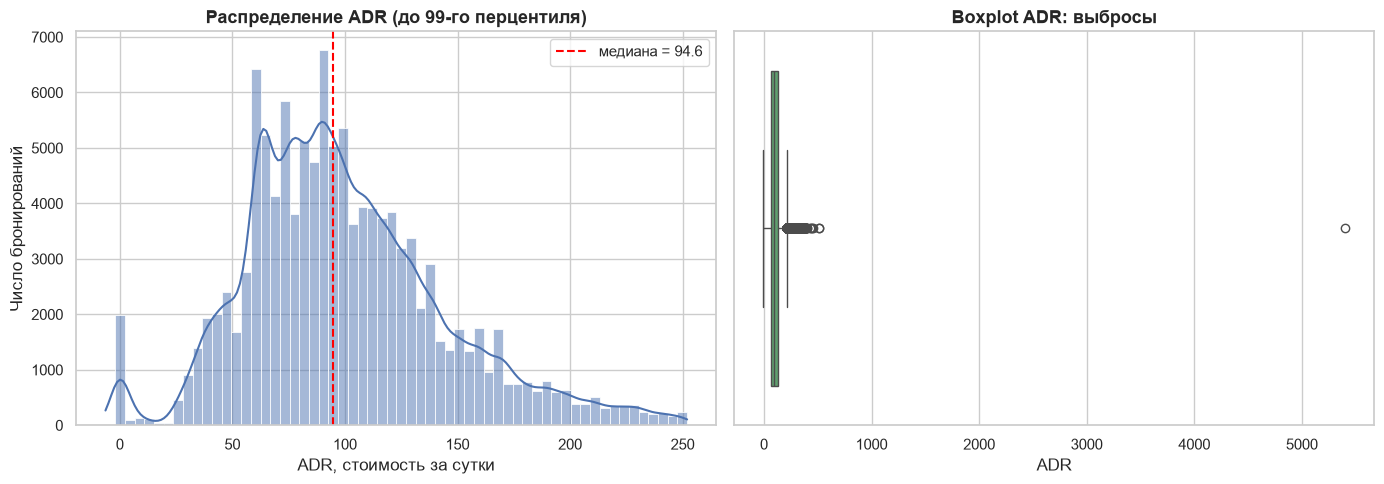

Медиана ADR: 94.58; среднее: 101.83; skew: 10.53
Значений выше верхней границы IQR: 3 793


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма до 99-го перцентиля, чтобы основная масса была видна
p99 = df["adr"].quantile(0.99)
sns.histplot(df.loc[df["adr"] <= p99, "adr"], bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["adr"].median(), color="red", linestyle="--", label=f"медиана = {df['adr'].median():.1f}")
axes[0].set_title("Распределение ADR (до 99-го перцентиля)")
axes[0].set_xlabel("ADR, стоимость за сутки")
axes[0].set_ylabel("Число бронирований")
axes[0].legend()

sns.boxplot(x=df["adr"], ax=axes[1], color="#55A868")
axes[1].set_title("Boxplot ADR: выбросы")
axes[1].set_xlabel("ADR")

plt.tight_layout()
plt.show()

print(f"Медиана ADR: {df['adr'].median():.2f}; среднее: {df['adr'].mean():.2f}; skew: {df['adr'].skew():.2f}")
print(f"Значений выше верхней границы IQR: {(df['adr'] > outliers.loc['adr', 'upper']).sum():,}".replace(",", " "))

**Интерпретация.** Распределение ADR правоскошенное: большинство бронирований сосредоточено в диапазоне 50–150, но есть длинный хвост дорогих бронирований. Среднее (101.8) заметно выше медианы (94.6) именно из-за хвоста. Boxplot показывает сотни выбросов справа, включая экстремальные значения выше 1000.

**Вывод.** `adr` требует обработки выбросов: обрезка по 99-му перцентилю или логарифмирование. Без этого модели, чувствительные к масштабу, будут смещены в сторону дорогих, но редких бронирований.

### График 2. Доля отмен по типу отеля

**Цель:** сравнить уровень отмен между городским и курортным отелем и оценить дисбаланс целевой переменной внутри каждой группы. Stacked bar показывает одновременно объём и долю.

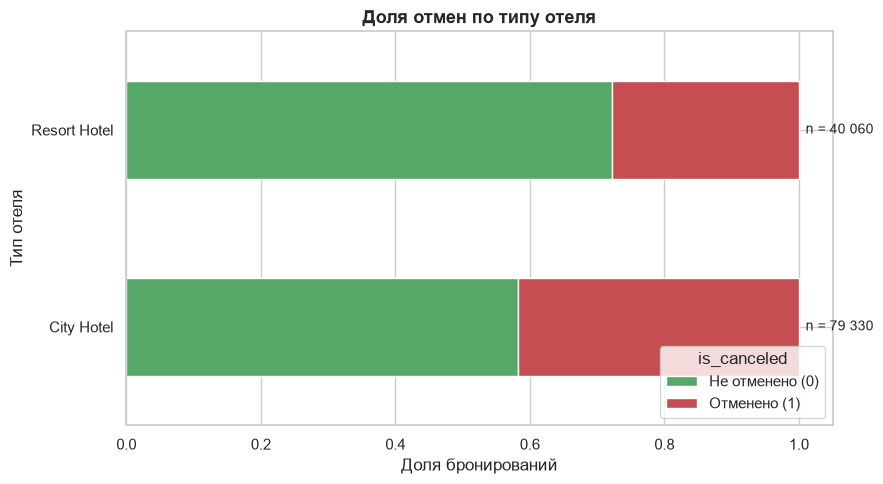

is_canceled   не отменено  отменено
hotel                              
City Hotel          0.583     0.417
Resort Hotel        0.722     0.278


In [16]:
ct = pd.crosstab(df["hotel"], df[target], normalize="index")
counts = df["hotel"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
ct.plot(kind="barh", stacked=True, ax=ax, color=["#55A868", "#C44E52"], edgecolor="white")
ax.set_title("Доля отмен по типу отеля")
ax.set_xlabel("Доля бронирований")
ax.set_ylabel("Тип отеля")
ax.legend(title="is_canceled", labels=["Не отменено (0)", "Отменено (1)"], loc="lower right")

for i, hotel in enumerate(ct.index):
    ax.text(1.01, i, f"n = {counts[hotel]:,}".replace(",", " "), va="center", fontsize=10)

plt.tight_layout()
plt.show()

print(ct.round(3).rename(columns={0: "не отменено", 1: "отменено"}))

**Интерпретация.** City Hotel: около 41.7% отмен, Resort Hotel — около 27.8%. Разница почти в 1.5 раза. Объём бронирований городского отеля более чем вдвое больше (79 330 против 40 060).

**Вывод.** Тип отеля — информативный признак: городской отель существенно чаще сталкивается с отменами. Это может быть связано с преобладанием деловых поездок и краткосрочным планированием. При этом дисбаланс классов внутри Resort Hotel слабее, поэтому метрики качества следует считать отдельно по группам.

### График 3. Связь срока бронирования (`lead_time`) с отменой

**Цель:** проверить гипотезу, что чем раньше гость бронирует номер, тем выше вероятность отмены. Boxplot сравнивает распределения `lead_time` для отменённых и состоявшихся бронирований.

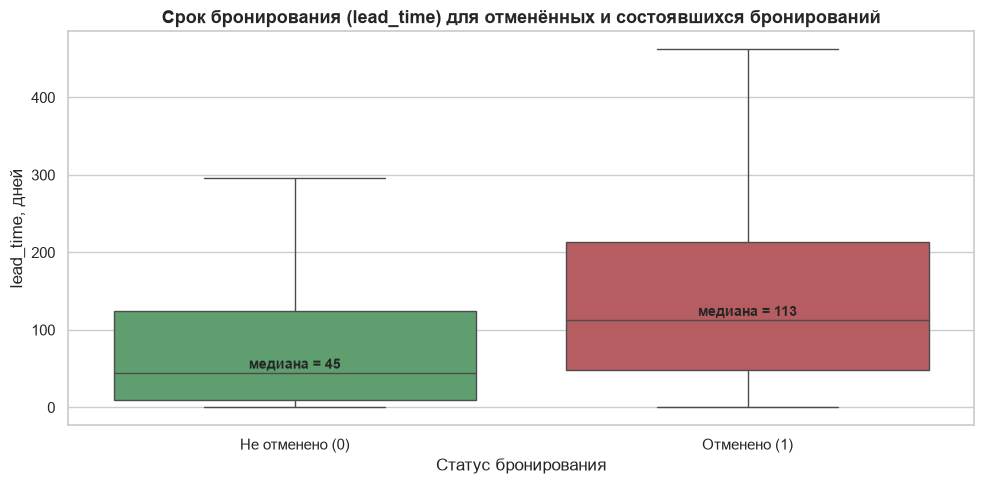

             count  median   mean
is_canceled                      
0            75166    45.0   80.0
1            44224   113.0  144.8


In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=df, x=target, y="lead_time", hue=target, ax=ax,
    palette=["#55A868", "#C44E52"], legend=False, showfliers=False
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Не отменено (0)", "Отменено (1)"])
ax.set_title("Срок бронирования (lead_time) для отменённых и состоявшихся бронирований")
ax.set_xlabel("Статус бронирования")
ax.set_ylabel("lead_time, дней")

medians = df.groupby(target)["lead_time"].median()
for i, v in enumerate(medians):
    ax.text(i, v + 5, f"медиана = {v:.0f}", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print(df.groupby(target)["lead_time"].agg(["count", "median", "mean"]).round(1))

**Интерпретация.** Медианный срок бронирования у отменённых — 113 дней, у состоявшихся — 45 дней; среднее различается ещё сильнее (144.8 против 80.0). Распределения заметно смещены, хотя и перекрываются.

**Вывод.** `lead_time` — один из самых сильных предикторов отмены: длинный горизонт планирования повышает неопределённость. Признак стоит оставить и, возможно, добавить бинарный флаг «бронирование более чем за 90 дней».

### График 4. Корреляционная матрица числовых признаков

**Цель:** выявить линейные зависимости и мультиколлинеарность, а также оценить, какие числовые признаки связаны с целевой переменной.

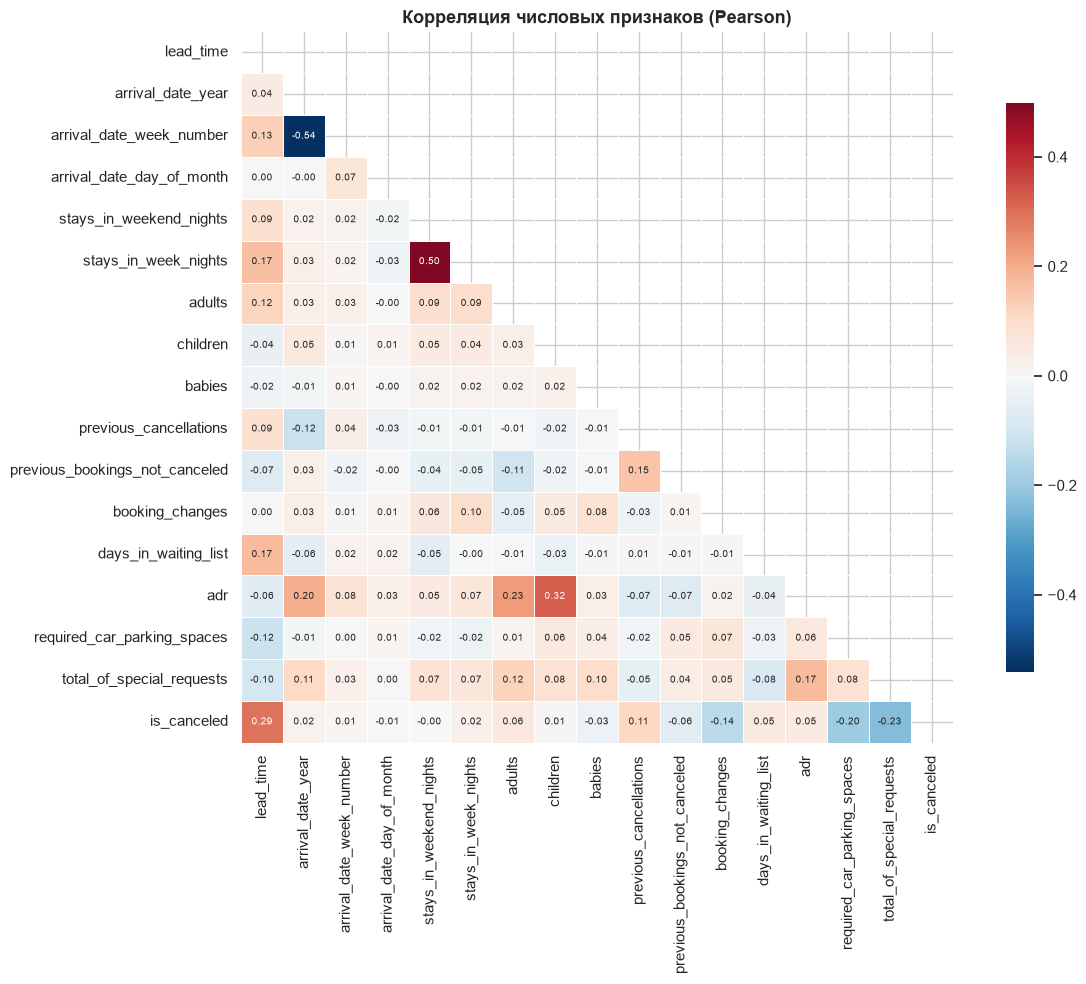

Наиболее сильные связи с is_canceled:
lead_time                      0.293
total_of_special_requests     -0.235
required_car_parking_spaces   -0.195
booking_changes               -0.144
previous_cancellations         0.110
adults                         0.060


In [18]:
corr_cols = numeric_cols + [target]
corr = df[corr_cols].astype("float64").corr(method="pearson")

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
    annot_kws={"size": 7}
)
ax.set_title("Корреляция числовых признаков (Pearson)")
plt.tight_layout()
plt.show()

print("Наиболее сильные связи с is_canceled:")
print(corr[target].drop(target).sort_values(key=lambda x: x.abs(), ascending=False).head(6).round(3).to_string())

**Интерпретация.** С целевой переменной сильнее всего связаны `lead_time` (r ≈ 0.29), `total_of_special_requests` (r ≈ −0.24), `required_car_parking_spaces` (r ≈ −0.20), `booking_changes` (r ≈ −0.14) и `previous_cancellations` (r ≈ 0.11). Большинство парных корреляций между признаками слабые (|r| < 0.4); заметные исключения — `arrival_date_year` ↔ `arrival_date_week_number` (−0.54, календарный артефакт) и число ночей в выходные ↔ будни (+0.50), что ожидаемо и не является проблемой.

**Вывод.** Линейные связи с отменой умеренные — одного `lead_time` недостаточно, нужна модель, учитывающая нелинейности и взаимодействия (градиентный бустинг, случайный лес). Отрицательная связь `booking_changes` и `total_of_special_requests` логична: если гость менял бронирование или оставлял пожелания, он активнее им пользуется и реже отменяет.

### График 5. Сезонность: число бронирований и доля отмен по месяцам

**Цель:** выявить сезонные закономерности спроса и проверить, меняется ли уровень отмен в течение года. Совмещаем объём (столбцы) и долю отмен (линия на второй оси).

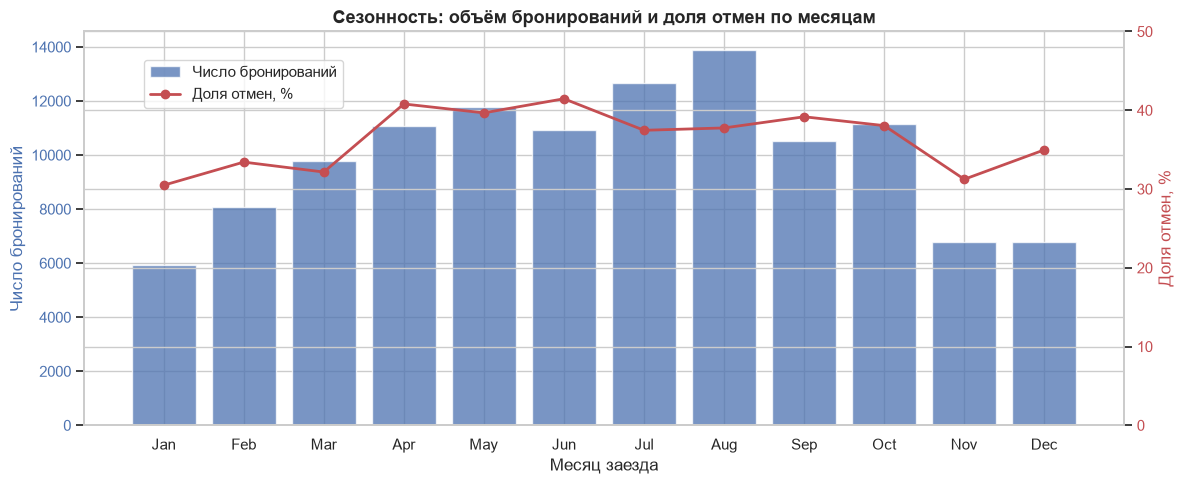

                    броней  отмен, %
arrival_date_month                  
January               5929      30.5
February              8068      33.4
March                 9794      32.2
April                11089      40.8
May                  11791      39.7
June                 10939      41.5
July                 12661      37.5
August               13877      37.8
September            10508      39.2
October              11160      38.0
November              6794      31.2
December              6780      35.0


In [19]:
monthly = (
    df.groupby("arrival_date_month", observed=True)
      .agg(bookings=(target, "size"), cancel_rate=(target, "mean"))
      .reindex(month_order)
)
x = np.arange(len(monthly))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(x, monthly["bookings"], color="#4C72B0", alpha=0.75, label="Число бронирований")
ax1.set_ylabel("Число бронирований", color="#4C72B0")
ax1.tick_params(axis="y", labelcolor="#4C72B0")
ax1.set_xticks(x)
ax1.set_xticklabels([m[:3] for m in monthly.index], rotation=0)
ax1.set_xlabel("Месяц заезда")

ax2 = ax1.twinx()
ax2.plot(x, monthly["cancel_rate"] * 100, color="#C44E52", marker="o", linewidth=2, label="Доля отмен, %")
ax2.set_ylabel("Доля отмен, %", color="#C44E52")
ax2.tick_params(axis="y", labelcolor="#C44E52")
ax2.set_ylim(0, 50)

ax1.set_title("Сезонность: объём бронирований и доля отмен по месяцам")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

print(monthly.assign(cancel_rate=lambda d: (d["cancel_rate"] * 100).round(1)).rename(columns={"bookings": "броней", "cancel_rate": "отмен, %"}))

**Интерпретация.** Пик бронирований приходится на июль–август (около 13–14 тыс. в месяц), минимум — на декабрь–январь. Доля отмен максимальна в апреле–июне (до 40–41%) и снижается к зиме. Таким образом, высокий сезон характеризуется и большим объёмом, и повышенным уровнем отмен.

**Вывод.** Сезонность — значимый фактор: месяц заезда следует использовать как признак (например, циклическое кодирование sin/cos вместо one-hot). Модель, обученная на всех месяцах без учёта сезонности, будет хуже предсказывать отмены в пиковые периоды.

### График 6. Топ-15 стран по числу бронирований

**Цель:** показать дисбаланс категорий и концентрацию спроса по странам, а также обосновать необходимость группировки редких значений.

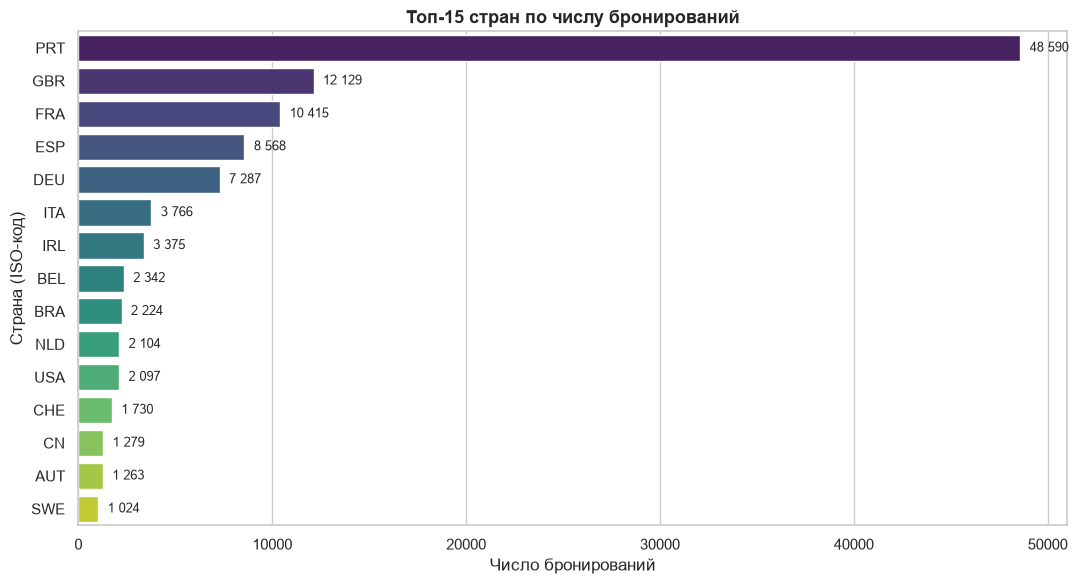

Топ-15 стран покрывают 90.6% всех бронирований;
остальные 162 стран — 9.4%.


In [20]:
top_countries = df["country"].value_counts().head(15)
other = len(df) - top_countries.sum()

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    x=top_countries.values, y=top_countries.index, ax=ax,
    palette="viridis", orient="h"
)
ax.set_title("Топ-15 стран по числу бронирований")
ax.set_xlabel("Число бронирований")
ax.set_ylabel("Страна (ISO-код)")

for i, v in enumerate(top_countries.values):
    ax.text(v + max(top_countries.values) * 0.01, i, f"{v:,}".replace(",", " "), va="center", fontsize=9)

plt.tight_layout()
plt.show()

print(f"Топ-15 стран покрывают {top_countries.sum() / len(df):.1%} всех бронирований;")
print(f"остальные {df['country'].nunique() - 15} стран — {other / len(df):.1%}.")

**Интерпретация.** Португалия (PRT) даёт около 40.9% всех бронирований, далее с большим отрывом идут Великобритания, Франция, Испания и Германия. Топ-15 стран покрывают 90.6% записей, остальные 162 страны — 9.4%.

**Вывод.** Признак `country` сильно несбалансирован: one-hot по всем 178 значениям создаст шум. Рационально оставить топ-10–15 стран, а остальные объединить в категорию `Other` либо заменить признак на его частоту (count encoding).

## 5. Итоговые выводы

### 5.1. Проблемы качества данных

| Проблема | Масштаб | Влияние |
|---|---|---|
| Полные дубликаты | 31 994 строки (26.8%) | Завышают вес повторяющихся объектов, риск утечки между train/test |
| Пропуски `company` | 94.3% | Признак почти неинформативен |
| Пропуски `agent` | 13.7% | Содержательны («прямое бронирование»), не ошибка |
| Пропуски `country` | 0.4% | Незначительно |
| Пропуски `children` | 4 значения | Незначительно |
| Выбросы `adr` | 3 793 значения (3.2%), max 5400 | Смещают средние и масштабно-чувствительные модели |
| Отрицательные `adr` | единицы | Логическая ошибка, требуется удаление |
| Бронирования без гостей / с 0 ночей | сотни | Логические аномалии |
| Высокая кардинальность `country`, `agent`, `company` | 177 / 333 / 352 | Разреженность после one-hot |
| Утечка `reservation_status`, `reservation_status_date` | 2 признака | Прямо определяют целевую переменную |
| Дисбаланс классов | 63% / 37% | Умеренный, не критичный |

### 5.2. Какие признаки требуют обработки

- **Удалить:** `reservation_status`, `reservation_status_date` (утечка целевой переменной).
- **Удалить или превратить в флаг:** `company` (94% пропусков); `agent` — в флаг «есть агент» либо сгруппировать редких.
- **Сгруппировать редкие категории:** `country` (топ-15 + Other), `agent`, `company`.
- **Обработать выбросы:** `adr` (обрезка по 1–99 перцентилям или логарифм), `lead_time` (лог-преобразование при линейных моделях).
- **Привести типы:** `children` → Int64, `agent`/`company` → string, `arrival_date_month` → упорядоченная категория.
- **Закодировать сезонность:** месяц заезда — циклическими признаками (sin/cos) или порядковым номером.
- **Добавить полезные производные признаки:** общее число ночей, общее число гостей, флаг «изменение типа номера» (`reserved_room_type != assigned_room_type`), флаг «длинный lead_time».

### 5.3. Ограничения данных

1. Данные охватывают только **два отеля в Португалии** за 2015–2017 гг. — выводы и модель плохо переносятся на другие страны и сети.
2. Признак `adr` содержит аномалии и, вероятно, ошибки ввода.
3. Дубликаты не позволяют однозначно восстановить уникальные бронирования — часть из них может быть реальными повторными заявками.
4. Отсутствуют сведения о гостях (демография), конкурентах и внешних факторах (погода, события), что ограничивает глубину анализа отмен.
5. Целевая переменная зависит от бизнес-процесса отеля (политика отмен), который мог меняться во времени.

### 5.4. Пригодность датасета

**Датасет пригоден** для разведочного анализа и обучения моделей бинарной классификации отмены бронирования. Он достаточно большой (119 тыс. записей), содержит разнообразные числовые и категориальные признаки, а целевая переменная имеет понятную бизнес-интерпретацию.

Перед моделированием обязательны: удаление дубликатов, устранение утечки (`reservation_status*`), обработка выбросов `adr`, группировка редких категорий и корректное кодирование сезонности. После этих шагов датасет можно использовать для построения модели прогнозирования отмен с реалистичной оценкой качества.

---
**Источник данных:** Antonio N., Almeida A., Nunes L. *Hotel booking demand datasets.* Data in Brief, 2019.
**Файл:** `data/hotel_bookings.csv` (119 390 × 32).